# HoloGuide: AI sees, rules decide, people oversee

HoloGuide checks a virtual four-step assembly (**base plate → gasket → cover → bolts**) and catches three mistakes:
a **missing part**, the **wrong part** (a green decoy cover) and parts in the **wrong order**. Everything runs
offline on one laptop.

1. A PyBullet scene renders the assembly from a fixed overhead camera.
2. An **inspector** sees only the image and reports an `Observation`: parts seen, confidence, one-sentence reason.
   It is evidence, not a decision.
3. Deterministic **rules** turn the Observation into a `Decision`: pass, block, needs review or hold.
4. The **workflow** advances only on a pass or a logged operator override with a typed reason. Every event goes
   to an audit log.

This notebook runs each piece, then the edge cases, then a small evaluation. It never downloads a model: Gemma
is used only if a local Ollama already serves `gemma3:4b`; otherwise the OpenCV inspector is used.

**Links:** code at <https://github.com/OmarElkott/HoloGuide> · run locally with `jupyter notebook notebooks/hologuide_demo.ipynb`.
On Kaggle the first cell clones that public repo and installs PyBullet; that is the only network use, and it is a
Kaggle convenience, not part of the shop-floor system.

## 0. Setup

Finds the repo (or, on Kaggle, clones it), loads `config/assembly.yaml` and shows the architecture.

In [1]:
import os, sys, json, subprocess, urllib.request
from datetime import datetime
from pathlib import Path
from time import perf_counter

REPO_URL = "https://github.com/OmarElkott/HoloGuide.git"

def find_root(start):
    for candidate in [start, *start.parents]:
        if (candidate / "config" / "assembly.yaml").exists():
            return candidate
    return None

ROOT = find_root(Path.cwd())
if ROOT is None:   # e.g. a Kaggle kernel: fetch the public repo and the two packages Kaggle lacks
    ROOT = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()) / "HoloGuide"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "pybullet", "ollama"], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.config import load_config

config = load_config()
RUN_DIR = ROOT / "outputs" / "notebook" / datetime.now().strftime("%Y%m%d-%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=False)
print(config.name, "-", len(config.steps), "steps; confidence threshold", config.confidence_threshold,
      "; AI timeout", config.ai_timeout_s, "s")
pd.DataFrame([{"step": s.id, "name": s.name, "adds": ", ".join(s.adds_parts)} for s in config.steps])

Sealed Cover Assembly - 4 steps; confidence threshold 0.7 ; AI timeout 20.0 s


,step,name,adds
0,1,Place base plate,base_plate
1,2,Insert gasket,gasket
2,3,Attach cover,cover
3,4,Install bolts,bolts


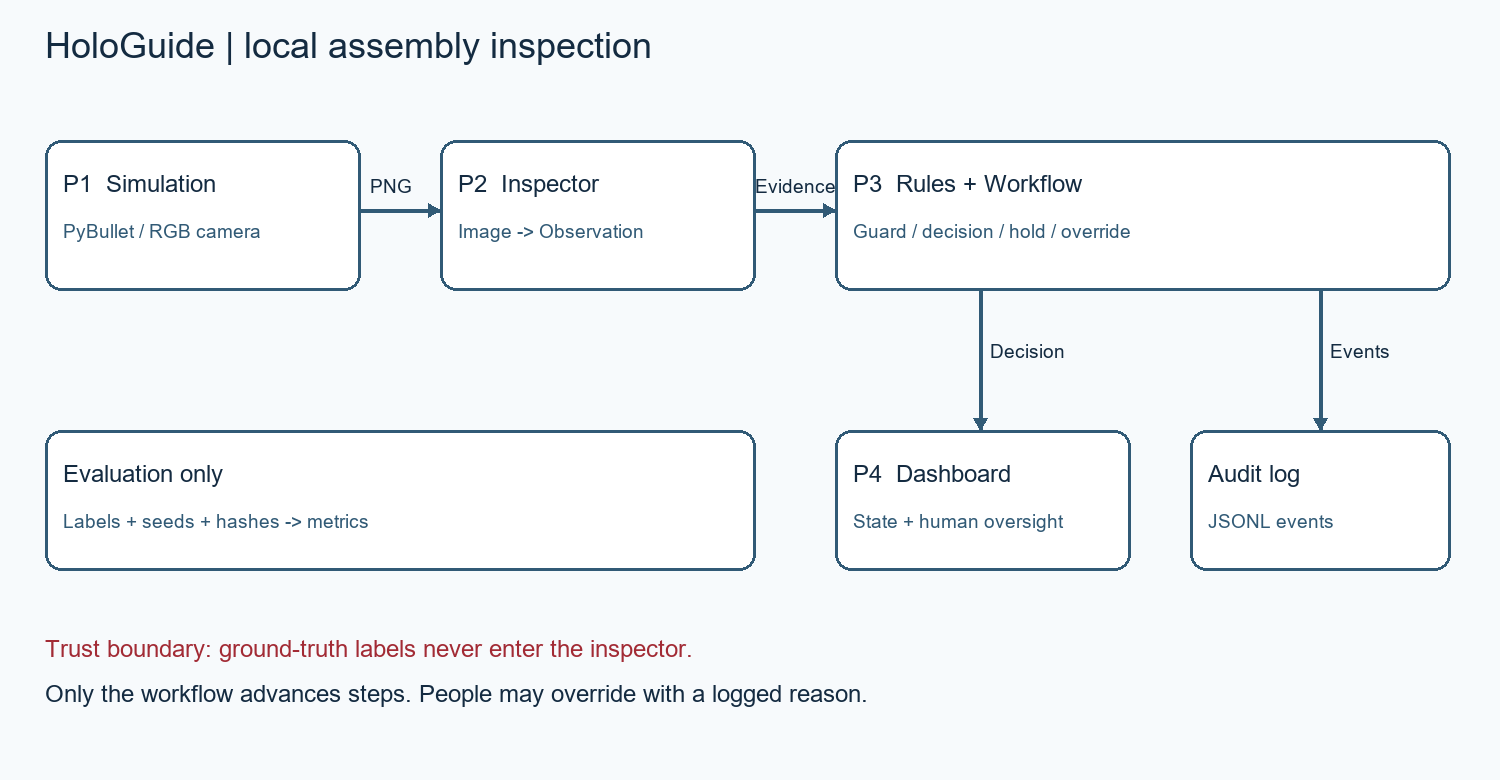

In [2]:
try:
    from IPython.display import display
    from PIL import Image
    display(Image.open(ROOT / "docs" / "architecture.png"))
except ImportError:
    print("Architecture diagram:", ROOT / "docs" / "architecture.png")

## 1. Choose an inspector

All inspectors share one contract, `inspect(image_path, step) -> Observation`. They never raise and never see the
simulator's ground truth.

| Inspector | What it does |
|---|---|
| `cv` | OpenCV colour masks + shape checks (no GPU, ~15 ms) |
| `gemma` | Gemma 3 4B through local Ollama, wrapped in the AI timeout |
| `hybrid` | OpenCV decides; Gemma only settles parts OpenCV is unsure about (the demo default) |

In [3]:
from src.vision import factories

def ollama_has_gemma(host="http://localhost:11434"):
    try:
        with urllib.request.urlopen(f"{host}/api/tags", timeout=1) as response:   # local only
            return any(m["name"].startswith("gemma3:4b") for m in json.load(response)["models"])
    except Exception:
        return False

INSPECTOR = os.environ.get("HOLOGUIDE_NOTEBOOK_INSPECTOR") or ("hybrid" if ollama_has_gemma() else "cv")
inspector = {"cv": factories.cv, "hybrid": factories.hybrid, "gemma": factories.gemma}[INSPECTOR](config)
print("Using", INSPECTOR, "->", type(inspector).__name__)

Using hybrid -> HybridInspector


## 2. Inspect one image by hand

Render the *missing gasket* mistake (the cover placed straight on the base plate) and check it as step 3.

In [4]:
from src.simulation.assembly_env import AssemblyEnv
from src.control.rules import RuleContext, evaluate

def render(parts, name):
    with AssemblyEnv(config, seed=0) as env:
        for part in parts:
            env.place_part(part)
        return env.render_to_file(str(RUN_DIR / name))

frame = render(["base_plate", "cover"], "missing_gasket.png")       # the gasket is missing
step = config.step(3)
observation = inspector.inspect(frame, step)                          # only the image path and the step
decision = evaluate(observation, step, config.confidence_threshold,
                    context=RuleContext.from_config(config, step))
print("Observation:", observation.model_dump_json(indent=2))
print("Decision:", decision.status.value, "-", decision.message, f"(decided by {decision.decided_by.value})")

Observation: {
  "parts_detected": [
    "base_plate",
    "cover"
  ],
  "missing_parts": [
    "gasket"
  ],
  "wrong_parts": [],
  "foreign_objects": [],
  "confidence": 0.95,
  "rationale": "OpenCV: saw Base plate, Cover. Bolts: 0 found."
}
Decision: block - Missing required part: Gasket. Add it and inspect Attach cover again. (decided by rule)


pybullet build time: Jan 29 2025 23:16:28


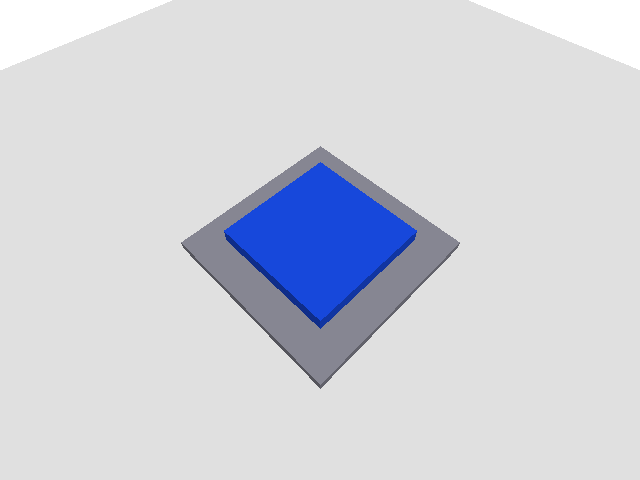

In [5]:
try:
    from IPython.display import display
    from PIL import Image
    display(Image.open(frame))
except ImportError:
    print("Image saved at", frame)

## 2b. What Gemma 3 4B itself reports

The hybrid rarely needs Gemma on these clean renders, so here Gemma is called **directly** on three scenes to
show its raw evidence. The model is never told the step (prompt v2 asks one yes/no question per colour); code
maps its answers to parts, and the **rules** make the call. Runs only if a local Ollama already serves
`gemma3:4b`; otherwise N/A.

In [6]:
if ollama_has_gemma():
    gemma = factories.gemma(config)
    cases = [("correct, step 2", ["base_plate", "gasket"], 2),
             ("missing gasket, step 3", ["base_plate", "cover"], 3),
             ("green decoy cover, step 3", ["base_plate", "gasket", "wrong_cover"], 3)]
    rows = []
    for label, parts, step_id in cases:
        image = render(parts, f"gemma_{step_id}_{len(rows)}.png")
        step_spec = config.step(step_id)
        started = perf_counter()
        obs = gemma.inspect(image, step_spec)              # image path + step spec only, no labels
        seconds = perf_counter() - started
        verdict = evaluate(obs, step_spec, config.confidence_threshold,
                           context=RuleContext.from_config(config, step_spec))
        rows.append({"scene": label, "Gemma saw": ", ".join(obs.parts_detected) or "nothing",
                     "confidence": obs.confidence, "Gemma's reason": obs.rationale,
                     "rules decision": verdict.status.value, "seconds": round(seconds, 2)})
    gemma_table = pd.DataFrame(rows)
else:
    gemma_table = "N/A: no local Ollama serving gemma3:4b here (e.g. on Kaggle). Dev-laptop results are in section 7."
gemma_table

,scene,Gemma saw,confidence,Gemma's reason,rules decision,seconds
0,"correct, step 2","base_plate, gasket",0.9,A dark grey square plate is clearly visible on...,pass,2.77
1,"missing gasket, step 3","base_plate, cover",0.9,A dark grey square plate is clearly visible on...,block,2.52
2,"green decoy cover, step 3","base_plate, gasket, wrong_cover",0.9,A flat grey square plate is clearly visible on...,block,4.72


## 2c. A job only Gemma can do: naming a foreign object

A tool or rag left on the assembly (foreign object debris, FOD) is a real escape on a shop floor. Neither model
handles it alone:

* **OpenCV** notices pixels that belong to no known part and draws a box around them, but cannot say *what* they
  are. On its own it can only send the step to review.
* **Gemma 3 4B** on the full frame misses small objects (in our probe it answered "no other object" for 6 of 6
  tool and rag scenes). Shown OpenCV's **crop** of the region, it names them.

So OpenCV says **where**, Gemma says **what**, and the **rules** decide: a named tool, cloth or debris gives
BLOCK with the object in the message. Any other answer, or a Gemma failure, gives Needs Review, never Pass.

The **name is a hint, not ground truth**: on held-out dataset v3 Gemma classified 60 of 60 regions as foreign
(so 60 of 60 were blocked) but named the right object in only 28 of 60 (a wrench is often called a screwdriver
or hammer). The block depends only on the kind; the name tells the operator where to look.

OpenCV alone -> needs_review | OpenCV: saw Base plate, Cover, Gasket. Bolts: 0 found. 0.1% of the image is an unrecognised object.
Unexplained region (x0, y0, x1, y1): (339, 188, 354, 231)


Hybrid       -> block | Foreign object in the work area: wrench (tool). Remove it and inspect Attach cover again.
Foreign objects reported: ['wrench (tool)']


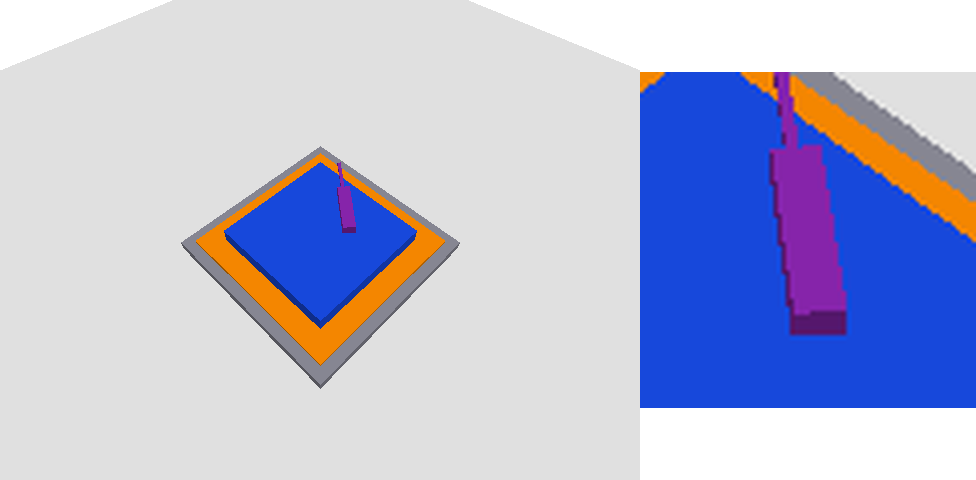

In [7]:
from src.vision.cv_inspector import CVInspector
from src.vision.foreign_objects import crop_region
from src.vision.hybrid_inspector import HybridInspector

def render_fod(kind, on_assembly, name):
    with AssemblyEnv(config, seed=7) as env:
        for part in ["base_plate", "gasket", "cover"]:
            env.place_part(part)
        env.place_foreign_object(kind, on_assembly=on_assembly)   # ground truth stays in the simulator
        return env.render_to_file(str(RUN_DIR / name))

fod_frame = render_fod("screwdriver", True, "fod_screwdriver.png")
step = config.step(3)
cv_only = CVInspector(config)
cv_obs = cv_only.inspect(fod_frame, step)
cv_decision = evaluate(cv_obs, step, config.confidence_threshold, context=RuleContext.from_config(config, step))
print("OpenCV alone ->", cv_decision.status.value, "|", cv_obs.rationale)
print("Unexplained region (x0, y0, x1, y1):", cv_only.last_details["unexplained_bbox"])

if ollama_has_gemma():
    fod_inspector = factories.hybrid(config)          # OpenCV + Gemma identifier
    fod_obs = fod_inspector.inspect(fod_frame, step)
    fod_decision = evaluate(fod_obs, step, config.confidence_threshold, context=RuleContext.from_config(config, step))
    print("Hybrid       ->", fod_decision.status.value, "|", fod_decision.message)
    print("Foreign objects reported:", fod_obs.foreign_objects)
else:
    print("Hybrid       -> N/A: no local Ollama serving gemma3:4b here (e.g. on Kaggle).")
try:
    from IPython.display import display
    from PIL import Image
    import io
    crop = Image.open(io.BytesIO(crop_region(fod_frame, cv_only.last_details["unexplained_bbox"])))
    pair = Image.new("RGB", (640 + 336, 480), "white")
    pair.paste(Image.open(fod_frame), (0, 0)); pair.paste(crop, (640, 72))
    display(pair)                                      # full frame | the crop Gemma sees
except ImportError:
    pass

## 3. Run a full scenario through the workflow

`ScenarioRunner` plays scripted operator actions: the mistake is injected, the step is **blocked**, the operator
fixes it, the step is re-inspected and the workflow continues to **Complete**.

In [8]:
from src.control.audit_log import AuditLog
from src.control.workflow import Workflow
from src.simulation.runner import ScenarioRunner

SCENARIO = "missing_gasket"     # correct | missing_gasket | wrong_cover | wrong_order
audit = AuditLog(RUN_DIR / "audit.jsonl")
with AssemblyEnv(config, seed=0) as env:
    workflow = Workflow(config, inspector, audit)
    result = ScenarioRunner(SCENARIO, env, workflow, RUN_DIR / "frames").run()
print(result)
assert result.completed, result.error

RunResult(scenario='missing_gasket', completed=True, fault_status='block', recovered=True, guard_blocked=False, recovery_s=0.08354024199979904, decisions=['pass', 'block', 'pass', 'pass', 'pass'], error=None)


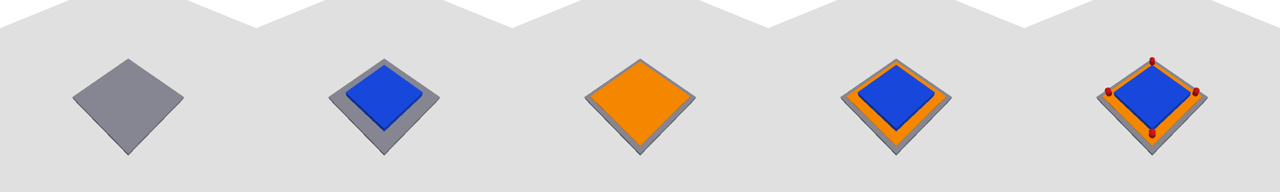

,frame,decision
0,001.png,pass
1,002.png,block
2,003.png,pass
3,004.png,pass
4,005.png,pass


In [9]:
frames = sorted((RUN_DIR / "frames").glob("*.png"))
try:
    from IPython.display import display
    from PIL import Image
    thumbs = [Image.open(f).resize((256, 192)) for f in frames]
    strip = Image.new("RGB", (256 * len(thumbs), 192), "white")
    for i, thumb in enumerate(thumbs):
        strip.paste(thumb, (256 * i, 0))
    display(strip)
except ImportError:
    pass
pd.DataFrame({"frame": [f.name for f in frames], "decision": result.decisions})

## 3b. The live line: motion, a watchdog and a safety interlock

A simulated gantry lowers each part into place frame by frame. A **deterministic motion watchdog** inspects only once
the scene has been still for 3 frames, so the AI never decides *when* to look. Every pick goes through the order
guard. A BLOCK, review, HOLD, refused pick or **E-STOP** stops the line, and only an operator action restarts it.
Each frame shows the **AI handoff**: who contributed, how long it took, and what the rules decided.

Below, a short shift of 6 units with seeded random faults. The operator is **scripted** here, and labelled on every
frame; in the dashboard a person clicks. The full 20-unit shifts with real Gemma are in `docs/decisions.md`.

Units: [(1, 'correct', '-'), (2, 'correct', '-'), (3, 'correct', '-'), (4, 'missing_gasket', 'caught'), (5, 'correct', '-'), (6, 'wrong_cover', 'caught')]


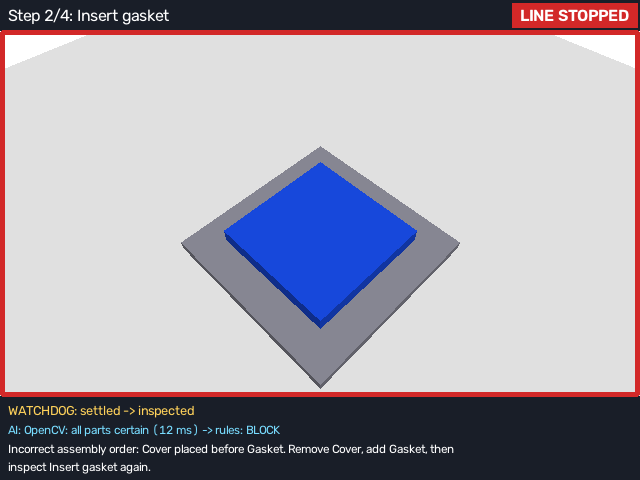

,units_completed,units_planned,faults_injected,faults_caught,faults_escaped,false_stops,holds,estops,mean_cycle_s,mean_downtime_per_stop_s,units_per_hour
0,6,6,2,2,0,0,0,0,7.02,2.0,512.8


In [10]:
from src.simulation.live_monitor import run_shift

shift, shift_frames = run_shift(config, inspector, RUN_DIR / "shift", units=6, fault_rate=0.5, seed=7)
print("Units:", [(r["unit"], r["scenario"], "caught" if r["caught"] else ("ESCAPED" if r["escaped"] else "-"))
                 for r in shift.results])
stopped = next((f for f in shift_frames if f[15, 630, 0] > 180 and f[15, 630, 1] < 80), shift_frames[-1])
try:
    from IPython.display import display
    from PIL import Image
    display(Image.fromarray(stopped))              # a frame where the line is stopped
except ImportError:
    pass
pd.DataFrame([shift.kpis()])

## 4. The audit log

Every action, inspection, decision and correction is one JSON line.

In [11]:
def audit_table(log):
    return pd.DataFrame([{
        "event": e["event_type"],
        "step": (e.get("current_step") or {}).get("id"),
        "next state": e.get("next_state"),
        "decision": (e.get("decision") or {}).get("status"),
        "detail": (e.get("decision") or {}).get("message") or e.get("reason") or e.get("part") or "",
    } for e in log.read_all()])

audit_table(audit)

,event,step,next state,decision,detail
0,scenario_started,NaN,None,None,
1,action_accepted,1.0,waiting,None,Base plate is allowed for Place base plate.
2,inspection_requested,1.0,inspecting,None,
3,inspection_passed,1.0,step_complete,pass,Step 1 verified: Place base plate. Continue to...
4,step_advanced,1.0,step_complete,pass,Step 1 verified: Place base plate. Continue to...
5,simulation_fault_injected,NaN,None,None,cover
6,inspection_requested,2.0,inspecting,None,
7,inspection_blocked,2.0,blocked,block,Incorrect assembly order: Cover placed before ...
8,scenario_correction,NaN,None,None,cover
9,scenario_correction_started,NaN,None,None,


## 5. Edge cases: unsure AI, slow AI and the operator

* An **unsure** observation (confidence below 0.70) goes to **Needs Review**; an operator approves it with a typed reason.
* An inspection that exceeds the **timeout** returns a safe zero-confidence observation and the workflow goes to
  **Hold**; an operator clears the hold, which does *not* approve the step.

`MockInspector` and `SlowInspector` are test doubles, used here only to force these paths.

In [12]:
from src.vision.inspector import MockInspector, SlowInspector, TimeoutInspector

edge_audit = AuditLog(RUN_DIR / "edge_cases.jsonl")
base_frame = render(["base_plate"], "base_plate.png")

unsure = Workflow(config, MockInspector(config, mode="uncertain"), edge_audit)
unsure.check_action("base_plate")
print("unsure AI ->", unsure.request_inspection(base_frame).status.value, "| state:", unsure.state.value)
approved = unsure.operator_override(True, "Visually confirmed the base plate is seated.", "operator-1")
print("override  ->", approved.status.value, "decided by", approved.decided_by.value, "| step now", unsure.current_step_id)

slow = TimeoutInspector(SlowInspector(MockInspector(config), delay_s=1.0), timeout_s=0.2)
held = Workflow(config, slow, edge_audit)
held.check_action("base_plate")
print("slow AI   ->", held.request_inspection(base_frame).status.value, "| state:", held.state.value)
held.clear_hold("operator-1", "Inspector restarted.")
print("hold cleared -> state:", held.state.value, "| step still", held.current_step_id)
audit_table(edge_audit)

unsure AI -> needs_review | state: needs_review
override  -> pass decided by operator | step now 2


slow AI   -> hold | state: hold


hold cleared -> state: waiting | step still 1


,event,step,next state,decision,detail
0,action_accepted,1,waiting,None,Base plate is allowed for Place base plate.
1,inspection_requested,1,inspecting,None,
2,inspection_needs_review,1,needs_review,needs_review,Inspection confidence 40% is below the require...
3,operator_override,1,None,pass,Operator operator-1 approved step 1: Visually ...
4,action_accepted,1,waiting,None,Base plate is allowed for Place base plate.
5,inspection_requested,1,inspecting,None,
6,inspection_hold,1,hold,hold,Inspection failed or returned no reliable evid...
7,hold_cleared,1,waiting,None,Inspector restarted.


## 6. A small evaluation you can rerun here

Generate a fresh labelled mini-dataset (labels stay in a separate CSV that the inspector never sees) and score the
chosen inspector with the project's evaluation runner. The full 200-image results are in section 7.

In [13]:
from src.simulation.dataset import generate
from src.evaluation.runner import run as evaluate_dataset

mini = RUN_DIR / "mini-dataset"
generate(mini, config=config, seed=2026, randomize=True, correct=8, per_fault=4)   # 20 images
rows, summary = evaluate_dataset(mini / "labels.csv", inspector, config, RUN_DIR / "mini-eval.csv")
print("False-block rate:", summary["false_block_rate"], "| median latency (s):",
      round(summary["latency"]["median_s"], 3))
pd.DataFrame([{"mistake type": k, "cases": v["count"], "accuracy": v["accuracy"]}
              for k, v in summary["accuracy_by_mistake_type"].items()])

False-block rate: 0.0 | median latency (s): 0.009


,mistake type,cases,accuracy
0,correct,8,1.0
1,missing_part,4,1.0
2,wrong_order,4,1.0
3,wrong_part,4,1.0


## 7. Full evaluation results

Measured on the dev laptop (RTX 3060 Laptop 6 GB, `gemma3:4b` 4-bit) over 200 images per dataset; v2 is
randomised (camera, lighting, offsets) and was held out from prompt tuning. When the run artifacts exist on this
machine they are loaded from `outputs/evaluation/`; otherwise the measured table committed in
`docs/decisions.md` is shown. Nothing here is estimated.

In [14]:
stems = [("OpenCV", "cv-v2-run1"), ("Gemma 3 4B (prompt v2)", "gemma-v2-run2"), ("Hybrid", "hybrid-v2-run1")]
paths = [ROOT / "outputs" / "evaluation" / f"{stem}.summary.json" for _, stem in stems]
if all(p.exists() for p in paths):
    results = []
    for (label, _), path in zip(stems, paths):
        s = json.loads(path.read_text())
        row = {"inspector": label, "dataset": "v2 (held out)"}
        row.update({f"acc {k}": v["accuracy"] for k, v in s["accuracy_by_mistake_type"].items()})
        row.update({"false-block rate": s["false_block_rate"], "median s": round(s["latency"]["median_s"], 3)})
        results.append(row)
    print("Source: this machine's outputs/evaluation/*.summary.json")
    results = pd.DataFrame(results)
else:   # artifacts are gitignored; fall back to the measured table committed with the code
    lines = (ROOT / "docs" / "decisions.md").read_text().splitlines()
    start = lines.index("## Results by inspector")
    table = []
    for line in lines[start + 1:]:
        if line.startswith("|"):
            table.append(line)
        elif table:
            break
    split = lambda line: [cell.strip() for cell in line.strip("|").split("|")]
    print("Source: docs/decisions.md (measured 2026-11-07)")
    results = pd.DataFrame([split(l) for l in table[2:]], columns=split(table[0]))
results

Source: this machine's outputs/evaluation/*.summary.json


,inspector,dataset,acc correct,acc missing_part,acc wrong_order,acc wrong_part,false-block rate,median s
0,OpenCV,v2 (held out),1.000,1.0,1.00,1.0,0.000,0.014
1,Gemma 3 4B (prompt v2),v2 (held out),0.925,1.0,0.85,1.0,0.075,3.245
2,Hybrid,v2 (held out),1.000,1.0,1.00,1.0,0.000,0.018


In [15]:
# Dataset v3 (seed 3030, held out): 40 correct, 10 of each earlier mistake, 60 foreign objects.
v3 = []
for label, stem in [("OpenCV", "cv-v3-run1"), ("Gemma 3 4B alone", "gemma-v3-run1"),
                    ("Hybrid + Gemma identifier", "hybrid-v3-run1"), ("Gemma-first + identifier", "gemma_first-v3-run1")]:
    path = ROOT / "outputs" / "evaluation" / f"{stem}.summary.json"
    if path.exists():
        s = json.loads(path.read_text())
        row = {"inspector": label}
        row.update({f"acc {k}": round(v["accuracy"], 3) for k, v in s["accuracy_by_mistake_type"].items()})
        row.update({"false-block rate": s["false_block_rate"], "median s": round(s["latency"]["median_s"], 3)})
        v3.append(row)
pd.DataFrame(v3) if v3 else "v3 run artifacts are not on this machine; see docs/decisions.md (Foreign objects)."

,inspector,acc correct,acc foreign_object,acc missing_part,acc wrong_order,acc wrong_part,false-block rate,median s
0,OpenCV,1.00,0.000,1.0,1.0,1.0,0.00,0.016
1,Gemma 3 4B alone,0.85,0.467,1.0,0.6,1.0,0.15,2.824
2,Hybrid + Gemma identifier,1.00,1.000,1.0,1.0,1.0,0.00,0.024
3,Gemma-first + identifier,0.85,1.000,0.9,0.6,1.0,0.00,3.013


## Takeaways

* **The AI reports, the rules decide.** No inspector output can advance the workflow by itself; low confidence,
  timeouts and failures all stop safely (Needs Review or Hold), and overrides need a typed, logged reason.
* **Why the rules, not Gemma, decide.** After prompt tuning, Gemma 3 4B catches every missing and wrong part on the
  held-out set, but it still accepts 15% of wrong-order images: it misses the orange gasket on a bare plate under
  some lighting. That is an unsafe failure, so it is a second opinion, not the decider.
* **Hybrid is the default.** OpenCV is perfect and about 200x faster at checking the known parts on these renders.
* **Gemma does the open-ended job.** OpenCV finds *where* an unrecognised object is; Gemma, shown only that crop,
  says *what* it is. On held-out dataset v3 the hybrid blocked 60 of 60 foreign objects with 0% false blocks,
  while Gemma alone passed 32 of 60 and OpenCV alone could only send them to review.
* **Gemma-first is the safe alternative.** Gemma reads every image and OpenCV can only send disagreements to review:
  no mistake image passed on v2 or v3, at the cost of 8-11% operator reviews.
* **Offline by design.** Everything runs on one laptop against a local Ollama; the demo never downloads a model.
* **Limits.** These are synthetic images; results do not prove physical-world performance. A real camera is the
  next step.